# ファインデックスの研究開発を半日で体験する
## 視野検査のばらつきを理解し、次回の測定値を予測する

**所要時間：4時間（休憩10分を含む）／CPUで実行／R・GPU・非公開データは不要**

作成・確認日：2026年11月8日（日本時間）。この教材は、公開求人と公開研究をもとに作成した独立の業務体験です。企業が配布・監修した教材ではありません。

### この半日で作るもの

- 30患者・360検査の品質確認表と視野マップ。
- 「前回値」「過去3回平均」「Ridge回帰」の比較表。
- 患者別・検査点別の誤差の可視化と、患者単位の不確実性評価。
- 入力を確認して52点の予測を返す小さな関数。
- そのまま研究ミーティングで説明できる研究メモ。

**問い：同じ人の過去3回の視野検査を使うと、次に記録された検査の感度を、前回値だけよりうまく予測できるか？**

到達点は、比較方法と結果の限界を説明することです。機械学習が勝つことは完了条件に含めません。対象は次回の**ノイズを含む測定値**で、疾病の有無、真の感度、長期進行を予測する課題ではありません。

### 開き方

1. [Google Colab](https://colab.research.google.com/)で、この `.ipynb` をアップロードするか、Jupyterで開きます。
2. CPUの通常環境で上から順番に実行します。各章の「考える」をメモしながら進めます。
3. データはNotebook内に小さな圧縮スナップショットとして同梱しています。データのダウンロードやRの導入は不要です。
4. 完成図・結果表・研究メモは、実行場所の `outputs/` に保存されます。

必要なライブラリは NumPy / pandas / Matplotlib / scikit-learn / IPython です。ローカル環境で不足する場合は同梱の `requirements.txt` を使用します。

### 4時間の進め方

| 経過時間 | 内容 | 手元に残すもの |
|---|---|---|
| 0:00–0:20 | 仕事の背景、仮説と評価単位を決める | 研究計画3行 |
| 0:20–0:50 | 読込、ID・日付・欠測・品質指標を監査 | QC表 |
| 0:50–1:20 | 学習患者の視野と変動を観察 | マップ・時系列 |
| 1:20–1:30 | 休憩 | — |
| 1:30–2:05 | 患者分割と過去3回→次回のデータ構成 | 分割と配列 |
| 2:05–2:40 | 基準法とRidgeを実行 | 3候補の予測 |
| 2:40–3:25 | 患者別・点別・感度帯別に誤差を調査 | 評価図と比較表 |
| 3:25–4:00 | 予測関数と研究メモを完成 | PoC・報告 |

時間が足りない場合も、平均化との比較・患者別評価・研究メモは残してください。Ridgeの数式の詳読とbootstrapの発展説明は後日に回せます。

## 0. 求人で求められる仕事との対応（20分）

[求人](https://hrmos.co/pages/findex/jobs/0000227)には、眼球運動・視野検査・網膜感度マップの解析、課題に応じたモデル構築、PoCと製品実装、共同研究が記載されています。ノイズ・個体差、生体理解、患者単位と検査点単位での安定性が重視されています。

そこから、次のような作業が多いと**推定**できます。日々の配分や社内の具体的な技術構成は確認できません。

| 想定する作業 | 本教材での体験 |
|---|---|
| 何を測定したデータか確認する | 1行・1列の意味、単位、盲点付近の位置を調べる |
| ノイズと生体の違いを切り分ける | 同一患者の反復検査と個人差を見る |
| 仮説を検証できる解析計画にする | 過去3回平均は単回値より安定する、という仮説を定義 |
| 適切なモデルを選ぶ | 単純な2方法と正則化線形回帰を比較 |
| 患者・検査点ごとの失敗を調べる | 患者別MAEと点別誤差マップを作る |
| チームに結果を渡す | 入力仕様を持つ予測関数と研究メモを作る |

GAPと標準視野計HFAの[共同研究（Miyake et al., 2024）](https://doi.org/10.1016/j.ogla.2024.05.003)では、全体の相関だけでなく一致度や不一致点の眼球運動を調べています。今回はHFA由来の公開視野データを使い、その「測定の吟味と誤差の調査」の一部を模擬します。GAPの生の眼球運動や社内アルゴリズムは使用しません。

**考える：**「入力」「予測対象」「評価の単位」をそれぞれ1文で書いてください。予測対象に「緑内障の診断」や「悪化」を書いた場合、今回のデータにその正解ラベルがあるか確認してください。

### 先に固定する解析方針

- 患者21人を学習、9人を評価に使用。分割のseedは固定します。
- 54測定点のうち位置地図で盲点付近と指定された2点を除き、52点を使用。
- 各患者を日付順に並べ、直近3回から次の1回を予測。
- 主解析は全360検査を保持。結果を見て患者や検査を除外しません。
- 主要指標は、患者別MAEをさらに患者間で平均した値（dB）。
- Ridgeの `alpha=10.0` は学習体験用に固定し、評価結果に合わせて変更しません。

これは小規模な探索PoCです。最良モデルの選択や精密な臨床性能の推定には、学習患者内の検証と独立した追加データが必要です。

In [1]:
# 0-A. 環境確認
import base64, gzip, hashlib, io, json, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
SEED = 20261108
HISTORY = 3
ALPHA = 10.0
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'matplotlib': matplotlib.__version__,
            'scikit-learn': sklearn.__version__}
print(VERSIONS)

{'python': '3.12.13', 'numpy': '2.3.5', 'pandas': '3.0.5', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1'}


## 1. データを読む・監査する（30分）

### 出典と構造

使用するのは、Rパッケージ `visualFields` の `vfpwgRetest24d2` です。作者の[データ一覧](https://imarinfr.r-universe.dev/datasets)と[公式マニュアル](https://cran.r-universe.dev/visualFields/doc/manual.html#vfpwgRetest24d2)で公開されています。CSVの提供先もありますが、本教材では再現性のため、固定したCRANソースのRデータをPythonでCSVへ変換したスナップショットを使います。

元の研究は [Artes et al. (2014)](https://openaccess.city.ac.uk/id/eprint/4999/) です。30人の開放隅角緑内障患者について1眼ずつを反復測定し、進行判定の偽陽性が患者ごとにどう異なるかを調べました。本教材はその研究のGPA解析の再現ではありません。

- **1行**：ある患者のある眼の1回の検査。
- `id`：患者ID。`eye`：右眼OD、左眼OS。
- `date`：検査日。`age`：年齢。
- `l1`～`l54`：各位置の視野感度（dB）。欠損は空欄等で表現され、0 dB自体を欠損扱いにはしません。
- `fpr` / `fnr` / `fl`：偽陽性率・偽陰性率・固視不良の割合。ここでは構造と分布を監査し、モデルの特徴には使いません。

パッケージのライセンス表示はApache License 2.0です。出典、原著、固定commit、SHA-256、日付変換の記録、ライセンスを同梱しました。CSV化で日付をISO形式にした以外の測定値は変更していません。

**考える：** 360検査、54測定点があるとき、独立した患者が19,440人いることになるでしょうか？

In [2]:
# @title 1-A. 同梱された公開データを展開（変更不要）
# CSVの圧縮スナップショット。pickle等の実行可能形式は使用しません。
SNAPSHOTS = {"vfpwgRetest24d2.csv":{"sha256":"2d387f3045b74dadd884c12f18c1a09ed7fe5b51168d85ebd34c61b6f14ae439","gzip_base64":"..."},"p24d2_coordinates.csv":{"sha256":"b75ecc679f2aa140aa5a4345314f311ca714db8ffe97055e21433695337756bf","gzip_base64":"H4sIAAAAAAACA1WSS47CMBBE95ylLMWfxPEFOAF7NCNYRIoATRgJbj/u9pAuS2xeq+mqlOtxX25PvPDGsp2/1+V2OW+P+/OweriC4HH8WrfrYQ1wkTCCKYFXRzg/ov7+eZJLhlkuGc5gKuBVP6C75KupqlN2DiplHEXKMImU4QimCbya0R2a0emUqpvrvz9hDOrD2KsP4yA+DKP4MExgElmjCXro9PMrlNHJzGrD2aCoDxvEQY3QQJ+RWN+RWJwQyksSavjuYydO6NVyk99zinOTt0FR+Z3ToPLG8nWEAd22NoM4oZNLrWnOCpK0azzQuHggfWOWEhCPWjketASp3i1CGmiGxBrizn93hodlYgMAAA=="},"LICENSE.visualFields.txt":{"sha256":"c71d239df91726fc519c6eb72d318ec65820627232b2f796219e87dcf35d0ab4","gzip_base64":"H4sIAAAAAAACA91aW5PbthV+969ANdPp7gwtO2nSNs6T4l03ah3tzmpdN5PJA0SCEmqSYAByteqv77ngRkm7dqdv9XgSSyIODs7lO985oBCf+bPoZblT4r0uVefUi2ee/IeyTptOfD1/XYi/yW6U9iC+fv36mycX7Yahf/Pq1X6/n0vaZm7s9lXDW7lXL3Dh/fXdT2uxWF2Jtzerq+X98ma1Fu9u7sSH9XUh7q5v726uPrzFrwt66mq5vr9b/vABvyEBX83Flap1pwdQzs1feG1m/kQz4XayaUSrZCcGOOmgbOuE7CpRmq7iVaI2VoxOFcKq3ppqLPHrwovCZyvtBqs3I34vpBMVbqkqsTmItSpZyFcg35pxuxPfCVPDBw3PmXJsVTcc62XsiWKl6Q9Wb3eDMPtOWQEqwUI9HIQch52x+t+0n5dzbsWwk4OATbdWwsJuSw95O2QKqK1sxDWJPlFi7PCApL0SsiQpQQswAzzrxRh4wCuoleOtwaCDNU0hpFXhQ0NKF3ga/HbsKlhWmrY1nZfkHxR7PexYDm84F++MJT360fYGIiZZNTo8+GjmpczoKE5c6EteavbKFuA+C15CJXTH/y7EYEQpwen4nJfCP5EFrGhlJ7cKnYf7urHcecUKsd8pOj54n/aVJDu3zF5jNIGUCw2akHvcTvcoqdY1WLNXtkTRF9++/v0lbWfAPGz4IGgc3ABWRx+Am6xyQSKI3KgOjFBqcOVEeqZncvnPZpyJC1iL/7Kzy9zr8Bdt8qCrEWVZkceHF6AeQVvtUBHQu9XOUcBTnHESkFtOQm0Nu5WQgpBe7XGk9VbVylpYTr/WZPFPuEVrKg1Hk5RVwcG6K5uRTAFJKDoziEa3GncHPzpTD3sML0cbglMqsH7IPRLkxfADRcj/Wm9HS7+DWxqVwcfN5l8QCqeqy+7A34E7xobyo7amhR/LnexA65AgEBWdwydlCCj6pvEfayEFm4fEFdMDehlHx4S06TUmlCHl/DG3EAlwBvh6cuAcveCkD4zeDuVw7raq0lIMhz4/9kdjP52Awh6+JI0JhzDSUgroLhwjJgCbzh+rlRUAyYPUjdw0If8zXCoQTTEAS+lDSUZcCOgGZoCHI7yxpeBhTWaVw4C1hSwUtPUiLuAA6lG2PewMCwHaIcx5IT656HsFOz9CMjVmf5mscKWsfgArPiiBBnGz4wjAPc7bwJ/eS2IbBMU30qHzOkrFCvfA6IfoYazCrchdmAv7nS53GRiAswaoAZCZVj1ociVGMZjG54lQYGFjwycQ4d2cZ5MXhlVOOYgUsr6EzUxDSQHL9FZ3sMupz0/xOOBUPUn/Qhybz1sPo9n7jsT7qmFVK3XMT9VLS5GCdqFjtMqq5gB50H0iw20gWjBOOtmqy+B0DUBka1lSkSiyGhmNeqIUWkeZOnn9LUK5r/FnPX6cAzFls/2iAX3ChVoa9UBhE59QDFeeiQRJhm1Dq+D3p5QvsqQYEPUNbN0E2HbjBrDDg0fgHRRdpDmp51OBNiIcP6EVwctU7p6tFjlRQVSm7THeNwqMWYMpniYvX1btxSyeaeZlcb2PsAyLVAMJaA2AcYFe2MiG4mhvcV1H5GPsvPUFZkFudJUMhXYaXEoWsr8rni1FEbvyPeBv0gkQUTe4uAFKCdKykhWpkDu4QbUuh3CouaPCElJSjfRPsPux8jFbiVwrN3qRwcgkCjJro92A45ajoypPO7aEl55GfiTES6VJPQYjTM8a4hGO4npdjmZ0kLyttJ8Q+mxiR4FyKae3HWE/hCL6iAx7NhIRrGYrsLcUea7OZ6cpfMSv47FDBn6W8uQGRHxsjzYVO1BmoyCegDIqQnJQOt8nJaFTv40QPw1uWxqwN5drJLxZ+jEQfT0Xf0Vahdu+jccPzEqsRy6uPlbPNjNZmuWorKBKisxAAiEEdCYWR7wAyCGcEhherwawTAg/gL6m2mvkGp3pXpLnHZwYP74E1mO32DiZg2yGw8vaKvikgdg9mBKB/KSa+/4PNwzdFqyAHOsxjk+QLsF5P25gLVgRArVvJAR6/AZ05lLr6BtPLPK+Laf5EYuJLJ/seKacE7awg/6YOehWIuj+H3jnApapfsAEg5ZjCBQJFHTcEF2Kns+aeQ/oOgjbyQdFLC8oRH20qWvkeVAEVAPwy/8FRDF2YMdEHPBE2bNCgplwMjQB+yjsKvu+wXbTdOB0sjJil1etbKQGe/Oz2eHAiiQkt27EzQ6y1zlpNWVnbQF9QkejdKh9eeJfuEtog02nfEUE+ANGElk9LTteEA7EHa6vtqA+k7ypcn6LPboi1Lq5WNbo/9gLOUAqjOnolEFvWQW5lfgzgZxv3C9SwYrc2hrnXpLB8BilGZE/8WfwvBSN3LtRD3jURm25CIDFgvKJExyh4nMARzWBFXe+1U5yyuScQzhW8EdLTBXEMBWbRmKgTKEZ9ZkSGo2UY77kBVbF1QFTFL0XYkW6QNgq+DIEX7QuSMM+sWIo+GYu7lQ+GZrT1q08JGQ7RiHAQR24zQSPnmF55BKkjbDZCCBHcYSMBv5vYkWets1cwp9AsiK1QmSQFFqtUuzl2jTQE3F9D9j15kXsqy75pCNE2hb1RfW43wC3ajgiglZOfWN3iH9ODiqpPhx3Et9TGQ17brI9eXCTqDT2Udi/81DHYghB+6A7jBPuHl22PUJcDGmUia37loyhWM505zLb2aoBEqwIvDlr4ak7AI2OD5dtHDdMAVFghqXqWPjoLhAWK4W8qcjIBIXokNLNn41HEGf0OYbUKXNj9AwySLnKEKGFKoPHRHNyxtkhFa7A4I8POjVadYmgFf3vGz909Wx1c798ez2D5HscyN6Ydn4PpNzZPnl2ZRBwJlNOLEv+ykSF1lOCD2VFPWYKOnXWrAhKEue8mRgPaoQMfBA6QvElds3EnLfwWbtSsIGMRkmH7VQ+pfdLUrYCMYJN3wQ1ZdAx2TpZaBJV7lkdvs/BfBJkeV5PB1BC1wlnsGRuUwU8lW9scWplGbheNuXyvcEZK9VHmUIEAjpAdhYItNVLPOQh+qbD+Rw0zEgslIQm9H7HXRji16mZM38TeeBWOg75oIdIzSsylKk6PrcIsQ6T2XwsG7Kq8N8W+508IjMpQXVvoS/JhIKt78AR+Zmon8LxRlWprhrbQFsnEROAhfu/4M5jTCMDhyEGmOFsMtG0Cnom5gF2PI4/NsxT9xZnTZS6CqKtNKxnAnA0+MpcgUL8OXKVcSSnkbVOWO4ZBp9Ge2eujFhMdldk6jPaFCltamoWD0+0Ivl0LqYSycOts2leUuDktmpShSPrxlkyUWmMo8lYJnYqR53AxCHfUrPjbwK4V00s0M3Fhw6qqCOnqUfYqNTY/pLE7IIkzjcOxywyG2ZlY6wnR1eJ6eOOx4McpnqbfPr837RmnmaRmlnAsAimrlW4feT1KzPgonh7Q/VlY7gpw7TdUnuHZYRUcyOUA6cqxRdBmAaZS/xGzC54QApWjC3RFno6CvyDzxDqyNSjKjOIJ+CNBrFqKy3fKx33Hv4u4E8AhYGAOITFjEdXhpBzYMqd3Qih4f2FGtOXcI0hW5ybRUaDUy9lH3Cm7z+CTj6G+eEQtEHjIk2dfJtq1W+j9rdHWNAd+ARLOrkUCr9p8XoatQErA+8o4YDeFbHpwEntyXw2ZFPwm68GZ0oAW+rPc3GlHbVOeGlbi4/AP8Euh5gEUdXNgRtY6ryxxUowQF6k5iVNwYrkMJ/7Lql6gbri0OC4Rc2fxvHlxLmXONcCyJ8t1mK5nokfFuvlOhj34/L+x5sP9+Lj4u5usbpfXq/FzV1+LX/zTixWP4u/L1dXQHc03wA/4nTUpZNowpUqG5OmDKI5qQw4dYAml0xFDZE9hVgw5v3y/v11AVZfvVyu3t0tV3+9/ul6dV+In67v3v4IWi5+WL5f3v9MIfRueb+6XvPrAwsv43ZxBw778H5xJ24/3N3erK+52vJtYYM3C6B/D5tqunWgmxnuCqfhAp6zprca6TkduIbowkco/hLiZvNSnjY6B5wIjxvgWjtCdmdKHdtkBnV/z0rT2Pyi9bSZ5dj7yxw+B5PiovdabnRDl+dLrLwC6E83kB4sA75qaNgJOkKnnY1awk0WBNCQjww6tW00sK9SXRbxtruYjHLj5Oez8X7BRAFn+o3eEKEj5bY4j4j3FmHLAd9AcHQ7fj4/GD0n5QOHMsFljaaN/USAXCtbuZ3O8HF1eCUgvRzgeoV369ntMyQUEFu+SkACwzNdvJDzQgNC48wN9MZxteU7c6zisVbjrfFxo0vWHCPGjPyN7rwzM1zNJwYXz96JB63w2I3hgN0aU+11k88OP0FRNn0vcUqInGBExWupm9FyNZJNPXaJ3FARPPMmCN4CYPDm9uCNlYPAwThEgn48iPMy4jBdVg+aLklr//oGZIA3Qni5wYvnDPhuLhYl1gS0QkBe3HmRCnWWFB93SN2n6Xp8WfjsdVtgoeXOGJ6C0qRzctlOM1fgbbUiPAGoIw1lVyo+RM9jUI9+B4o71Xb4akkaiLFZm6C7MJvGT6GIt7xC2EHmy1ctcB7MF99faTe57oEG40ezx06IW8loMLJnJjidj95o6ZrsNiRybn8tQkNc/zUCaYJR0peYTrpFSYieJkVZGPiZMPZMumZ8xoTnfCfb1NE2laqhXeEVwIyrM6NzaVtCokCuoxVTOo/WptsyPzkGTIauHJtVHqIWp3PjzcGTjXSgA1og2TSS+X0WjRltjLpwAF+vrrCunnsNjn5f3N7CI8t/vkEX0rQAEPXgX1/IX93D30iVfbxLwtfrvnBB4V+jmE4TAq02kDUW2vAhTDWK1MnXWjWVE1AgINkZ9Dd4S6kgMme//DpLTQpOJny1O4RgIlT1XV/WSc/FxZXp/hDfF8hyNAj/3aWgbp3aVAf0AiIBKH7Uw3cHWdnO7mYxV9wB8PwxXoRSU88KAE7AwsbhBRU/7eekAcXpWY4biDJkrNx2Ec3sQzEOV6sblV5ZoRvSoInDhTNQjgbXiMEzrBXTm0//8guqCYGn4328t1y4d43jmTTkkLbc4Y01B0O6TPzlAH9+Fb+Q3qDn0S3rr/S4D5Iq65mm4VPkL4SKC3wgvnN5+T2KCP0IAgGXLz8+DzRed74NJWiMERUpTtb1mw1Ny+RkZBcCWQ4h3D/3yul74O6r9fVLUJmWfAlDf4p7+HfOXuRTyom9gnr4CkP2wFMM/H+k34F4k9nWSk1UCEFOtAZiBo7WbUcIOKAEUBa64zf7/LQk8XV3eq75i/8AvARde10sAAA="},"provenance.json":{"sha256":"44c070d1a3b6128b805544adc32201e5097cd70c9cf52e5511d3ac1a3dbb2322","gzip_base64":"H4sIAAAAAAACA8VWTW/cNhC9+1cMFgXaAlmtRH3Hp8BxAQNBHayDXooioMjhig0lCiS1thvkv3cobWyn9SGHJgUMw8sZzrz3OG/WH88ANhMXH/gBNy9hc9R+5uYXjUb6zYsYPKLz2o4xmCVpUq+nwvHxvbDDoEOMyAILUaRNVZaS5ZWkX0oVqi6aoi2F4qIuOlHXfL3M59Bb9+S6SEvBZC1zjlWd5wyxVW0hKta2vGiZwJynbdZm63WjBY5+gfuKoPcIb9YTYEm6png7O4GeUj7Sx8hCTbeHPQb0gRWSJU7yhyCFZ2diuT6Eyb/c7Ry/TQ469HM3e3TCjgHHkBDeXeS9eyrS7mup7yQPfPccjhefUfies7KKQBoVb6XEv+xYlnepKIqmS1UrsK5KUWGDbdbwKlVlLlqOqcxElqeyyVtRyQY3S8lPa+WNsWLgk//fSD/t/wxZlslcsbQRkqcyTxlnVZFWtcoqyao8DkbesLLmArM4BlWbNk3Zlky2bds0HfuS7OvLm4v91dt3V9e/Jk8xJ+EufG/2T7A8Rzxl9GQFT+usYhmvkddNWaZKSpU2Hb1kW1dFVfC8EGVTpiyjnKwpOt4VWV5kmH1J/M3VxeWvN5f/DWk9cKdH5Whgs93X2nN3gvAcV1FnJFMrVZvVrFKizGhSsauZzLMGRVU2LK1YzXLWMVW3JEiLTS2FykuZEuMT17MT3w2BfbKZ9hB4ZxDwbrIuoATu4eLmt3PYw2seECS/9+D1KBCytk63aUY/sNaI6cHC1c01pVGuD8T84M9htDAg97OjhCM3M3oQPR8PKBO4sNZJPcb8f3RWzg5wmvgfpsXkcHknzCwpOFk9Bg+GVTuTl6Al6a2Vpkh3D4E22bq4gC7/6KGjhnaY7EhZ8NMesm3HPcqfk9MOfsDwfmFCpVY13lGh004nNtYRcALEY9iDHoHHsoMdwelDH7Z4j/BYiwjwARO4piAdGKCVZWzwyR4G7Zx1Hu62/E57kNpPht+Dsg6ub+CWBsnOARxSKYwagqetrIM+6nBPHcw8jD6Bt4QH3ZGE67WHR+Qg5+XSYCUaQ3+dnxqCHc2qzqkjyXX3BeIVgFbge3sba3ARyANgUK30VHQDWKep1aLDvyXEY3wNEb9Wfl8N9U1Xw373oOvJLt++n7GcHub7dVxdQO2o2x+r3vyIPPhHjV8ZQ6PqghZ64tEaPWXAwfCZuvPFgz1yE3oaIMO9pzeEydkDzVD0PhjeofHJZ0Jx8n2Y5T0tAD8PcfB1CGRPQQOlBTc0SOTpkWZEzSaOiwvbgG44Ofuh0Nu5M9r3NGlxJ0TXLA4m65Ss2NI6AU94l8nzc/cnigA1SPSTDjFpxUCfhdPTMtxWQcbgFvEDQfAr+kfciwwPLdXkPi8c7hD+QmfPIegBd2SRZXyXc7KCwN4aetOt0R+iiUcfooqPdUkslFosdwJ3BwxApoteGvEuelVEs9ICpH9IXpDaAQ4zpzcPSIe0eBbEpDJplCzPePbp7G9/PeC3NAoAAA=="}}
DATA = Path('data')
DATA.mkdir(exist_ok=True)
SNAPSHOT_BYTES = {}
for name, item in SNAPSHOTS.items():
    raw = gzip.decompress(base64.b64decode(item['gzip_base64']))
    assert hashlib.sha256(raw).hexdigest() == item['sha256'], name
    SNAPSHOT_BYTES[name] = raw
    target = DATA / name
    if not target.exists():
        target.write_bytes(raw)
    elif target.read_bytes() != raw:
        print(f'{name}: ローカルファイルは変更済み。保持し、解析には同梱版を使います。')
df = pd.read_csv(io.BytesIO(SNAPSHOT_BYTES['vfpwgRetest24d2.csv']), parse_dates=['date'])
coords = pd.read_csv(io.BytesIO(SNAPSHOT_BYTES['p24d2_coordinates.csv']))
provenance = json.loads(SNAPSHOT_BYTES['provenance.json'])
print('data:', df.shape, 'coordinates:', coords.shape)

data: (360, 64) coordinates: (54, 4)


In [3]:
# 1-B. 構造の監査：この段階で結果に応じた除外・補完はしない
locs54 = [f'l{i}' for i in range(1, 55)]
blind = coords.loc[coords['is_blind_spot'], 'point'].tolist()
locs = [c for c in locs54 if c not in blind]
coords52 = coords.set_index('point').loc[locs]
df = df.sort_values(['id', 'eye', 'date']).reset_index(drop=True)
df['visit'] = df.groupby(['id', 'eye']).cumcount() + 1
df['gap_days'] = df.groupby(['id', 'eye'])['date'].diff().dt.days

qc = {
    'participants': int(df['id'].nunique()),
    'eyes': int(df[['id','eye']].drop_duplicates().shape[0]),
    'exams': len(df),
    'missing_sensitivities': int(df[locs54].isna().sum().sum()),
    'duplicate_id_eye_date': int(df.duplicated(['id','eye','date']).sum()),
    'min_sensitivity_db': float(df[locs54].min().min()),
    'max_sensitivity_db': float(df[locs54].max().max()),
    'blind_spot_columns': blind,
    'constant_metadata': [c for c in ['time','duration','fpr','fnr','fl','type']
                          if df[c].nunique(dropna=False) == 1],
    'max_gap_days': float(df['gap_days'].max())
}
print(json.dumps(qc, ensure_ascii=False, indent=2))
display(df.groupby(['id','eye']).size().rename('exams').reset_index().head())
display(df[['fpr','fnr','fl']].agg(['min','max','nunique']))
display(df.loc[df['gap_days'] > 35, ['id','eye','date','gap_days']])
assert df['id'].nunique() == 30
assert df.groupby(['id','eye']).size().eq(12).all()
assert df.groupby('id')['eye'].nunique().eq(1).all()
assert len(locs) == 52 and blind == ['l26','l35']
assert not df.duplicated(['id','eye','date']).any()
assert np.isfinite(df[locs].to_numpy(dtype=float)).all()
assert (df[locs].to_numpy() >= 0).all()
(OUT / 'qc.json').write_text(json.dumps(qc, ensure_ascii=False, indent=2), encoding='utf-8')

{
  "participants": 30,
  "eyes": 30,
  "exams": 360,
  "missing_sensitivities": 0,
  "duplicate_id_eye_date": 0,
  "min_sensitivity_db": 0.0,
  "max_sensitivity_db": 43.0,
  "blind_spot_columns": [
    "l26",
    "l35"
  ],
  "constant_metadata": [
    "time",
    "duration",
    "fpr",
    "type"
  ],
  "max_gap_days": 175.0
}


,id,eye,exams
0,1,OD,12
1,2,OD,12
2,3,OD,12
3,4,OS,12
4,5,OD,12


,fpr,fnr,fl
min,0,0.00,0.0
max,0,0.17,0.5
nunique,1,6.00,21.0


,id,eye,date,gap_days
73,7,OS,2007-10-29,116.0
74,7,OS,2008-04-21,175.0
75,7,OS,2008-09-24,156.0


### 監査で見つかること

1. 30人・30眼・360検査で、各人12検査あります。右17眼、左13眼です。
2. 位置地図の `bs` に対応する `l26`・`l35` は盲点付近です。値の大小で選ばず、測定位置の定義に基づき除きます。
3. `fpr` はすべて0、`time`・`duration` はすべて `00:00:00` です。このファイルから「全検査が高品質」「検査時間は0秒」とは結論できません。
4. 資料では12回を毎週実施した短期研究と説明されていますが、公開ファイルには116・175・156日の間隔があります。いずれもID 7です。原因を推測で修正せず、**日付順で次に記録された検査**と表現します。予測には未来の検査日や間隔を使いません。
5. 検査間隔35日はこの一覧表示のための便宜的な閾値です。主解析から除外する閾値ではありません。

**実務メモ：**「資料と値が一致しない」という発見には、解析を止めて照会すべきものと、制約を明示してPoCを続けられるものがあります。今回は後者として進めます。年率の進行速度の推定は行いません。

## 2. 学習患者を分け、視野の変動を観察する（30分）

最初に患者IDで学習・評価を分けます。形状や欠測などの監査は全体で行いましたが、以下の探索的な生理学的観察は学習患者だけに限定します。

同じ人の検査は、病態や個人特有の視野パターンを共有しています。検査行を無作為に分割すると、評価したい「学習に使っていない人での性能」と違う問いになってしまいます。[scikit-learnのグループ分割](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)を使って、この重複を防ぎます。

In [4]:
# 2-A. 21人/9人を固定して保存
splitter = GroupShuffleSplit(n_splits=1, test_size=9, random_state=SEED)
train_rows, test_rows = next(splitter.split(df, groups=df['id']))
train_ids = np.sort(df.iloc[train_rows]['id'].unique())
test_ids = np.sort(df.iloc[test_rows]['id'].unique())
assert set(train_ids).isdisjoint(set(test_ids))
assert (len(train_ids),len(test_ids)) == (21,9)
train_df = df[df['id'].isin(train_ids)].copy()
print('train IDs:', train_ids.tolist())
print('test IDs :', test_ids.tolist())
split_record = {'seed': SEED, 'train_ids': train_ids.tolist(), 'test_ids': test_ids.tolist()}
(OUT / 'patient_split.json').write_text(json.dumps(split_record,indent=2),encoding='utf-8')

train IDs: [1, 3, 4, 6, 8, 9, 10, 12, 13, 15, 17, 19, 22, 23, 24, 25, 26, 27, 28, 29, 30]
test IDs : [2, 5, 7, 11, 14, 16, 18, 20, 21]


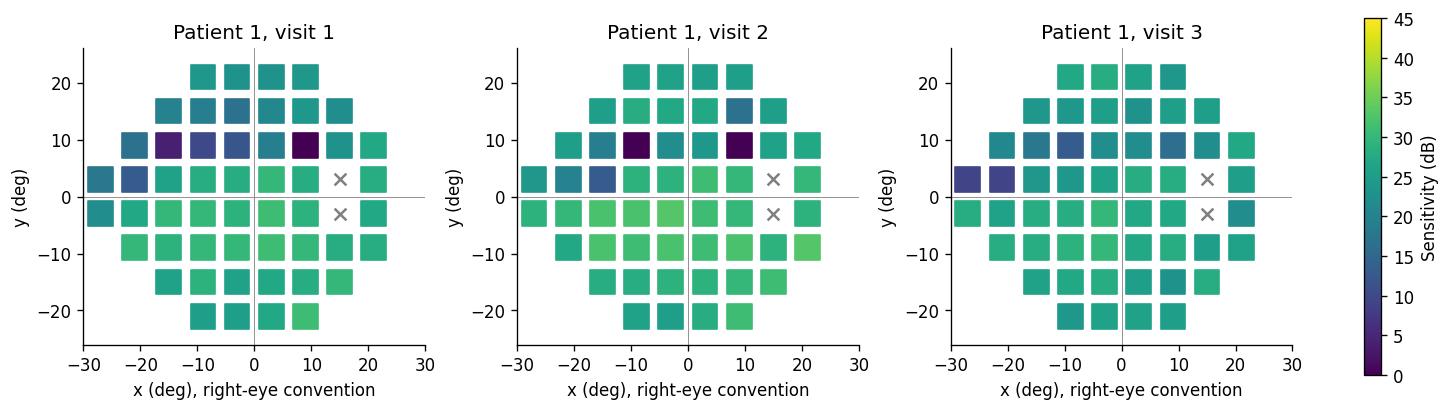

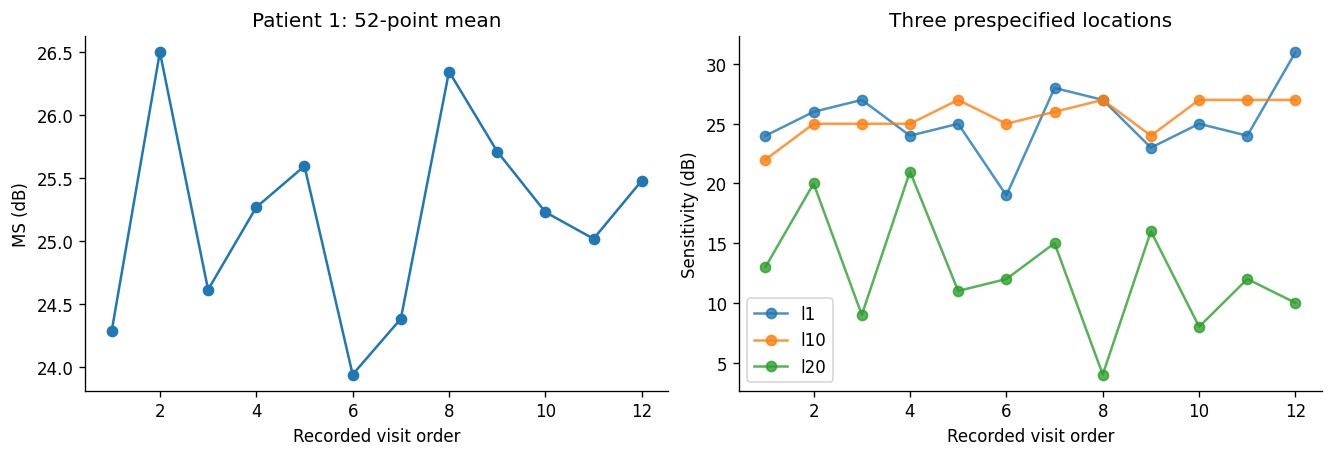

In [5]:
# 2-B. 位置地図。左右を右眼基準にそろえていることを明記する
def map_values(ax, values, title, vmin=0, vmax=40, cmap='viridis'):
    sc = ax.scatter(coords52['x'], coords52['y'], c=values, s=220,
                    marker='s', cmap=cmap, vmin=vmin, vmax=vmax)
    ax.scatter([15,15], [3,-3], marker='x', s=50, color='gray')
    ax.axhline(0, color='gray', linewidth=.5)
    ax.axvline(0, color='gray', linewidth=.5)
    ax.set(xlim=(-30,30), ylim=(-26,26), aspect='equal', title=title,
           xlabel='x (deg), right-eye convention', ylabel='y (deg)')
    return sc

example_id = int(train_ids[0])  # 結果の見栄えで患者を選ばない
example = train_df[train_df['id'] == example_id].sort_values('date')
fig, axes = plt.subplots(1,3, figsize=(12,3.8), constrained_layout=True)
for ax, k in zip(axes, [0,1,2]):
    sc = map_values(ax, example.iloc[k][locs].to_numpy(dtype=float),
                    f'Patient {example_id}, visit {k+1}', vmax=45)
fig.colorbar(sc, ax=axes, label='Sensitivity (dB)', shrink=.8)
fig.savefig(OUT / '01_three_fields.png', dpi=160, bbox_inches='tight')
plt.show()

ms = example[locs].mean(axis=1)  # Mean sensitivity。MDではない
fig, axes = plt.subplots(1,2, figsize=(11,3.7), constrained_layout=True)
axes[0].plot(example['visit'], ms, 'o-', label='Mean sensitivity')
axes[0].set(xlabel='Recorded visit order', ylabel='MS (dB)',
            title=f'Patient {example_id}: 52-point mean')
for point in ['l1','l10','l20']:
    axes[1].plot(example['visit'], example[point], 'o-', label=point, alpha=.8)
axes[1].set(xlabel='Recorded visit order', ylabel='Sensitivity (dB)',
            title='Three prespecified locations')
axes[1].legend()
fig.savefig(OUT / '02_retest_variation.png', dpi=160, bbox_inches='tight')
plt.show()

### 生理学・測定としての読み方

感度は刺激強度の検出閾値から得る測定値です。dBは対数尺度なので、dBの平均と線形な光強度の平均は同一ではありません。ここでは装置が出力したdB値の予測という問いに合わせ、dBのまま扱います。

低感度点で大きな変動が見られても、1回の低下だけで病態の進行とはいえません。応答の変動、注意、測定条件、検査への慣れなど複数の説明があり、今回のデータだけで原因は特定できません。

図は全眼を**右眼基準の共通座標**で描いています。これはパッケージの列番号と整合する表示です。左眼の臨床的な見え方をそのまま再現する場合は、x軸を反転する必要があります。視野上の上下左右と網膜上の位置も区別します。

52点の単純平均は **MS（mean sensitivity）** です。年齢・位置ごとの正常値等を用いた **MD（mean deviation）** と呼びません。

**考える：** 同じ点の値が上下する理由を、測定側と生体側から1つずつ挙げてください。今回のデータでどこまで検証できますか？

**ここで10分休憩。**

## 3. 過去3回→次の1回を作る（35分）

患者ごとに、検査1・2・3回目から4回目、2・3・4回目から5回目、という窓を作ります。12回から9窓が得られます。

| 配列 | 形状 | 意味 |
|---|---|---|
| `history` | 270 × 3 × 52 | 270窓、過去3検査、52点 |
| `X` | 270 × 104 | 各点の過去3回平均52個＋前回値と平均の差52個 |
| `Y` | 270 × 52 | 次の検査の52点 |

270窓は30人から作った関連する反復観測です。独立した270人ではありません。評価は9患者・81窓になります。

この設計は**逐次的な1回先予測**です。評価患者の次の検査が実際に終われば、その実測値を以後の履歴に使います。最初の3検査だけから残り9検査を予測する多段予測とは異なります。学習済みRidgeの重みは評価患者で更新しません。

`X` の後半の差分は「前回が、最近の平均からどの程度ずれたか」を表します。これは単回の変動をどこまで反映すべきか、線形モデルに学習させるための入力です。

In [6]:
# 3-A. 未来の値・未来の日時をXへ入れない
histories, targets, metadata = [], [], []
for (pid, eye), g in df.groupby(['id','eye'], sort=True):
    g = g.sort_values('date').reset_index(drop=True)
    values = g[locs].to_numpy(dtype=float)
    for j in range(HISTORY, len(g)):
        h = values[j-HISTORY:j]
        assert g.loc[j-1,'date'] < g.loc[j,'date']
        histories.append(h)
        targets.append(values[j])
        metadata.append({'id': int(pid), 'eye': eye,
                         'target_visit': int(g.loc[j,'visit']),
                         'history_last_date': g.loc[j-1,'date'],
                         'target_date': g.loc[j,'date'],
                         'gap_days': float(g.loc[j,'gap_days']),
                         'target_fl': float(g.loc[j,'fl'])})
history = np.stack(histories)
Y = np.stack(targets)
meta = pd.DataFrame(metadata)
mean3 = history.mean(axis=1)  # axis=1 は「3検査」の方向
last = history[:,-1,:]
X = np.concatenate([mean3, last-mean3], axis=1)
is_train = meta['id'].isin(train_ids).to_numpy()
is_test = meta['id'].isin(test_ids).to_numpy()
assert history.shape == (270,3,52) and X.shape == (270,104) and Y.shape == (270,52)
assert (is_train.sum(),is_test.sum()) == (189,81)
assert np.all(is_train ^ is_test)
assert set(meta.loc[is_train,'id']).isdisjoint(set(meta.loc[is_test,'id']))
print('history, X, Y:', history.shape, X.shape, Y.shape)
print('training / evaluation windows:', is_train.sum(), is_test.sum())
display(meta.head())

history, X, Y: (270, 3, 52) (270, 104) (270, 52)
training / evaluation windows: 189 81


,id,eye,target_visit,history_last_date,target_date,gap_days,target_fl
0,1,OD,4,2008-08-27,2008-09-03,7.0,0.06
1,1,OD,5,2008-09-03,2008-09-10,7.0,0.13
2,1,OD,6,2008-09-10,2008-09-17,7.0,0.00
3,1,OD,7,2008-09-17,2008-09-24,7.0,0.00
4,1,OD,8,2008-09-24,2008-10-01,7.0,0.06


### リークを防ぐ3つの区別

1. **個人の重複**：学習患者と評価患者を完全に分けます。
2. **時点の重複**：予測時点で入手できる過去3回だけから特徴を作ります。全12回平均や未来の検査日時を特徴にしません。
3. **前処理の学習**：平均・標準偏差を推定する `StandardScaler.fit` は学習患者にだけ適用します。

評価患者の過去3回を入力として使うこと自体は、この課題で想定した運用です。一方、その患者の未来の検査をモデルの学習や設定選びに使えば、評価の意味が変わります。[前処理とリークの公式解説](https://scikit-learn.org/stable/common_pitfalls.html)

**考える：** `df.groupby('id')[locs].transform('mean')` で全12回の平均を作り、各時点の入力にしたら何が起きますか？

## 4. 3つの方法を比較する（35分）

### 前回値と3回平均

位置を $p$ とすると、前回値は $\hat y_{t+1,p}=y_{t,p}$、3回平均は $\hat y_{t+1,p}=(y_{t,p}+y_{t-1,p}+y_{t-2,p})/3$ です。患者内で計算するため、この2つには他患者を用いる学習段階がありません。

### 平均化が効くかもしれない理由

仮に真の感度 $\mu$ が一定で、$y_t=\mu+\epsilon_t$、独立・平均0・分散 $\sigma^2$ の測定誤差を仮定すると、前回値予測の誤差分散は $2\sigma^2$、3回平均では $4\sigma^2/3$ になります。平均化で入力側のノイズを減らしても、次回の観測ノイズは残るためです。

これは仮定の下での計算です。実際の誤差に相関があったり、真の感度が変化したりすれば結果は変わります。変化を平均化でならすと、その変化への反応が遅れることもあります。

### Ridge回帰

[Ridge回帰](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)は、入力 $X$ と出力 $Y$ の線形関係を、係数を大きくしすぎない制約とともに学習します。標準化した $X$ に対し、おおむね次の目的関数を小さくします。

$$\|Y-XW-b\|_F^2+\alpha\|W\|_F^2$$

前半は予測誤差、後半は係数の大きさへの罰則です。$\alpha$ を大きくすると係数を抑える力が強くなります。本教材の104入力・52出力では、多くの係数を少数患者から推定します。線形モデルでも過学習の可能性があります。52出力を一度に指定しますが、出力同士の誤差共分散を直接モデル化するものではありません。

`Pipeline` は標準化と回帰を一体にし、学習時だけ前処理の値を推定するための仕組みです。`alpha=10` は教育用の固定値で、最適な値だと主張するものではありません。

In [7]:
# 4-A. 固定モデルを学習。評価側にはfitを使わない
model = make_pipeline(StandardScaler(), Ridge(alpha=ALPHA, solver='svd'))
model.fit(X[is_train], Y[is_train])
preds = {'last': last[is_test].copy(),
         'mean3': mean3[is_test].copy(),
         'ridge': model.predict(X[is_test])}
y_test = Y[is_test]
test_meta = meta.loc[is_test].reset_index(drop=True)
assert all(p.shape == y_test.shape and np.isfinite(p).all() for p in preds.values())
print('Evaluation patients:', test_meta['id'].nunique(), 'windows:', len(test_meta))
print('Predicted points per window:', y_test.shape[1])
print('Ridge negative predictions:', int((preds['ridge'] < 0).sum()))
# 負値なども黙ってクリップせず、このモデルの性質として評価・記録する

Evaluation patients: 9 windows: 81
Predicted points per window: 52
Ridge negative predictions: 36


## 5. 患者・点・感度帯ごとに評価する（45分）

### 患者を等しく扱うMAE

まず、各患者について全評価回・全52点の絶対誤差を平均します。その患者別MAEを9人で平均します。

$$MAE_i=\frac{1}{T_i\,52}\sum_t\sum_p |y_{itp}-\hat y_{itp}|,\qquad MAE_{macro}=\frac{1}{9}\sum_i MAE_i$$

単位はdBです。「平均して何dBずれたか」を読みます。MAEが小さいほど、この課題の次回値に近いという意味です。臨床的に十分な誤差かどうかの閾値は、この教材からは決められません。

今回の各患者の回数は同じなので単純な全点平均と数値は一致しますが、将来欠測や回数差が生じたときにも患者を等しく扱う定義を明示します。

,patient_macro_MAE_dB,worst_patient_MAE_dB,negative_predictions
last,2.1189,2.9167,0
mean3,1.7927,2.5050,0
ridge,2.9706,5.6095,36


,last,mean3,ridge
id,,,
2,2.107,1.868,2.707
5,1.333,1.104,1.340
7,2.692,2.293,3.569
11,1.714,1.430,1.736
14,1.588,1.267,1.550
16,1.376,1.116,1.620
18,2.447,2.108,5.610
20,2.897,2.444,3.721
21,2.917,2.505,4.882


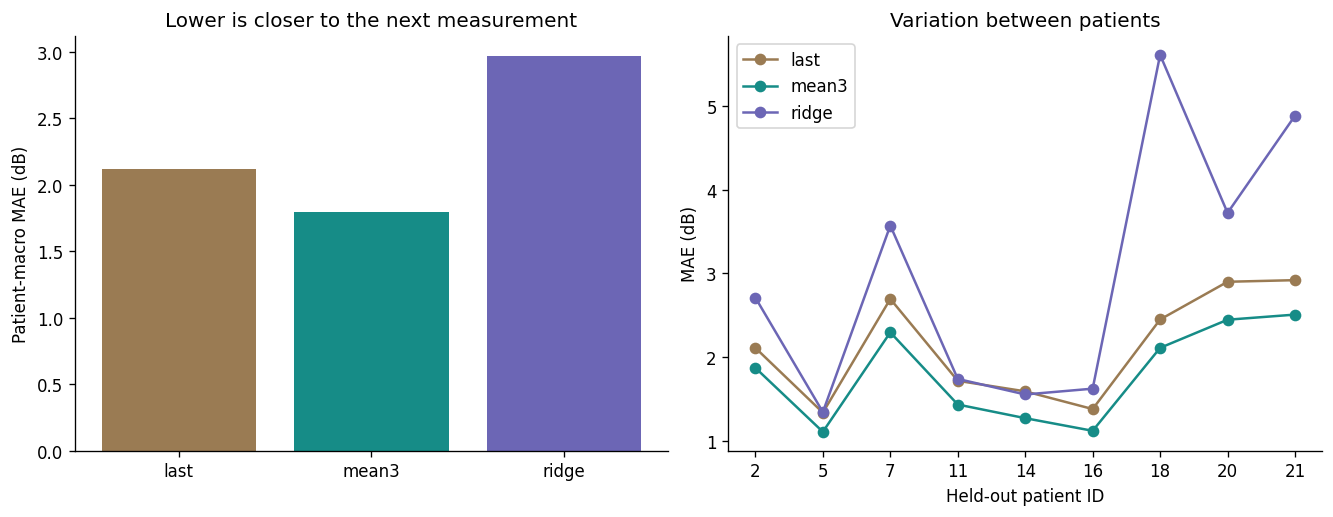

In [8]:
# 5-A. 患者別、集団平均、対応のある差
patient_mae = pd.DataFrame(index=test_ids)
patient_mae.index.name = 'id'
for name, pred in preds.items():
    per_window = np.abs(pred-y_test).mean(axis=1)
    patient_mae[name] = (pd.DataFrame({'id': test_meta['id'], 'mae': per_window})
                         .groupby('id')['mae'].mean())
metrics = pd.DataFrame({
    'patient_macro_MAE_dB': patient_mae.mean(),
    'worst_patient_MAE_dB': patient_mae.max(),
    'negative_predictions': {name: int((p < 0).sum()) for name,p in preds.items()}
})
display(metrics.round(4))
display(patient_mae.round(3))
metrics.to_csv(OUT / 'metrics.csv', encoding='utf-8-sig')
patient_mae.to_csv(OUT / 'patient_mae.csv', encoding='utf-8-sig')

fig, axes = plt.subplots(1,2, figsize=(11,4.2), constrained_layout=True)
colors = {'last':'#9a7b53','mean3':'#168c87','ridge':'#6c66b5'}
axes[0].bar(metrics.index, metrics['patient_macro_MAE_dB'],
            color=[colors[n] for n in metrics.index])
axes[0].set(ylabel='Patient-macro MAE (dB)', title='Lower is closer to the next measurement')
for name in preds:
    axes[1].plot([str(i) for i in patient_mae.index], patient_mae[name],
                 'o-', label=name, color=colors[name])
axes[1].set(xlabel='Held-out patient ID', ylabel='MAE (dB)', title='Variation between patients')
axes[1].legend()
fig.savefig(OUT / '03_model_comparison.png', dpi=170, bbox_inches='tight')
plt.show()

In [9]:
# 5-B. 患者単位のpaired bootstrap。負の差ならAの方が誤差が小さい
def paired_patient_bootstrap(a, b, repetitions=5000, seed=SEED):
    differences = (patient_mae[a] - patient_mae[b]).to_numpy()
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(differences), size=(repetitions, len(differences)))
    boot = differences[idx].mean(axis=1)
    lo, hi = np.quantile(boot, [.025,.975])
    return {'comparison': f'{a} - {b}', 'mean_difference_dB': float(differences.mean()),
            'ci_2.5%': float(lo), 'ci_97.5%': float(hi), 'patients': len(differences)}
ci = pd.DataFrame([paired_patient_bootstrap('mean3','last'),
                   paired_patient_bootstrap('ridge','mean3')])
display(ci.round(4))
ci.to_csv(OUT / 'paired_bootstrap.csv', index=False, encoding='utf-8-sig')

,comparison,mean_difference_dB,ci_2.5%,ci_97.5%,patients
0,mean3 - last,-0.3262,-0.3777,-0.2781,9
1,ridge - mean3,1.1779,0.5765,1.9514,9


### 不確実性の範囲

同じ9患者のモデル間の差を作り、その**患者を単位**に復元抽出しています。52点や81窓を独立に再標本化して、見かけの標本数を増やしてはいません。

この区間は、固定した学習済みモデルについて、評価9人の経験分布から得る目安です。学習患者を選び直す場合の変動、他施設・他機器での変動は含みません。9人という小さな評価集団なので、区間も不安定です。

**考える：** 集団平均で良い方法が、すべての患者で良いでしょうか？また、モデル間の差が0付近のときに「同等」と断定できるでしょうか？

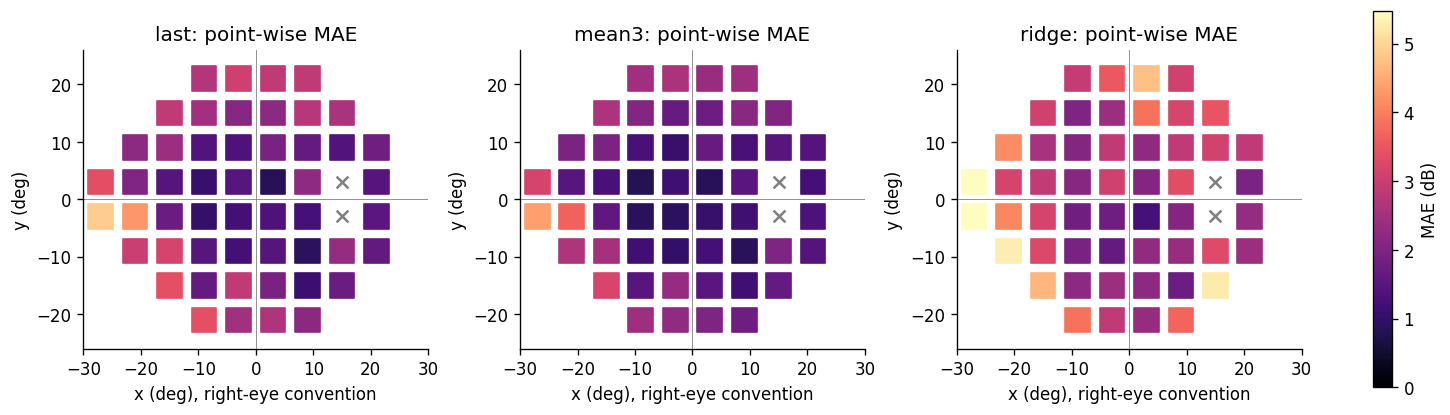

,prior_band,method,patients_with_points,point_observations,patient_macro_MAE_dB
0,0-<15 dB,last,5,308,6.341
1,0-<15 dB,mean3,5,308,6.235
2,0-<15 dB,ridge,5,308,8.984
3,15-<25 dB,last,9,697,3.481
4,15-<25 dB,mean3,9,697,2.925
5,15-<25 dB,ridge,9,697,3.696
6,25+ dB,last,9,3207,1.494
7,25+ dB,mean3,9,3207,1.249
8,25+ dB,ridge,9,3207,2.389


In [10]:
# 5-C. 同じ重みで患者別平均を作ってから、点ごとに集計
point_mae = {}
for name, pred in preds.items():
    per_patient = [np.abs(pred[test_meta['id'].eq(pid).to_numpy()] -
                          y_test[test_meta['id'].eq(pid).to_numpy()]).mean(axis=0)
                   for pid in test_ids]
    point_mae[name] = np.stack(per_patient).mean(axis=0)
fig, axes = plt.subplots(1,3, figsize=(12,4), constrained_layout=True)
vmax = max(float(v.max()) for v in point_mae.values())
for ax, name in zip(axes, preds):
    sc = map_values(ax, point_mae[name], f'{name}: point-wise MAE', vmax=vmax, cmap='magma')
fig.colorbar(sc, ax=axes, label='MAE (dB)', shrink=.8)
fig.savefig(OUT / '04_pointwise_errors.png', dpi=170, bbox_inches='tight')
plt.show()
pd.DataFrame(point_mae, index=locs).to_csv(OUT/'point_mae.csv', encoding='utf-8-sig')

# 将来の正解値ではなく、予測時に知っている過去3回平均で層別する
prior = mean3[is_test]
bands = [('0-<15 dB',0,15), ('15-<25 dB',15,25), ('25+ dB',25,np.inf)]
band_rows = []
for label, lo, hi in bands:
    mask = (prior >= lo) & (prior < hi)
    for name, pred in preds.items():
        per_patient = []
        for pid in test_ids:
            rows = test_meta['id'].eq(pid).to_numpy()
            selected = mask[rows]
            if selected.any():
                per_patient.append(float(np.abs(pred[rows]-y_test[rows])[selected].mean()))
        band_rows.append({'prior_band': label, 'method': name,
                          'patients_with_points': len(per_patient),
                          'point_observations': int(mask.sum()),
                          'patient_macro_MAE_dB': float(np.mean(per_patient)) if per_patient else np.nan})
band_metrics = pd.DataFrame(band_rows)
display(band_metrics.round(3))
band_metrics.to_csv(OUT/'sensitivity_bands.csv',index=False,encoding='utf-8-sig')

### 感度帯別評価の注意

15 dB・25 dBという区切りは、誤差の記述に用いる教材上の区分です。診断基準や重症度分類ではありません。各区分に含まれる患者数も併記します。

低感度の領域は平均化で改善するでしょうか。床に近い値、局所的な欠損、点ごとの異なるばらつきなどを仮説として考えます。ただし、誤差表だけでその生理的原因を特定することはできません。

### 大きく外れた1例を調べる

次はRidgeの**患者別MAEが最大の人**を、結果を見て選ぶというルールを明示して調べます。失敗の調査目的で選んだ例で、典型例やモデル選択の根拠としては扱いません。

This is an error-selected case, not a representative example.


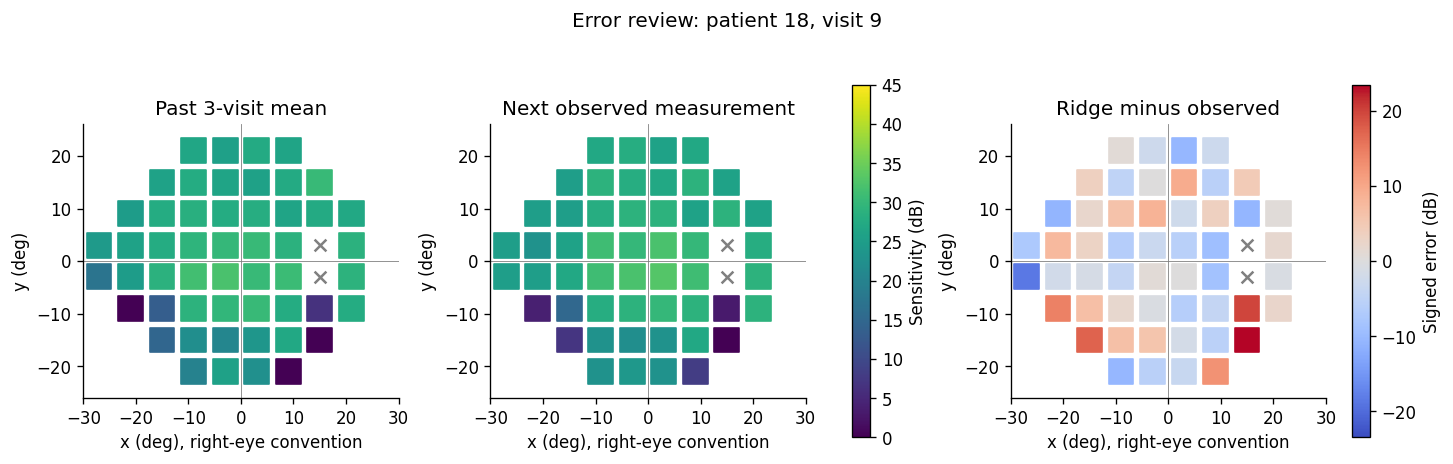

,id,eye,target_visit,history_last_date,target_date,gap_days,target_fl
59,18,OS,9,2008-11-06,2008-11-12,6.0,0.12


In [11]:
# 5-D. 失敗例の調査。選び方を記録する
worst_id = int(patient_mae['ridge'].idxmax())
within = np.flatnonzero(test_meta['id'].eq(worst_id).to_numpy())
ridge_window_error = np.abs(preds['ridge']-y_test).mean(axis=1)
worst_k = int(within[np.argmax(ridge_window_error[within])])
fig, axes = plt.subplots(1,3, figsize=(12,4), constrained_layout=True)
sc_sens = map_values(axes[0], mean3[is_test][worst_k], 'Past 3-visit mean', vmax=45)
map_values(axes[1], y_test[worst_k], 'Next observed measurement', vmax=45)
fig.colorbar(sc_sens, ax=axes[:2], label='Sensitivity (dB)', shrink=.8)
delta = preds['ridge'][worst_k] - y_test[worst_k]
limit = max(1., float(np.abs(delta).max()))
sc = map_values(axes[2], delta, 'Ridge minus observed', vmin=-limit, vmax=limit, cmap='coolwarm')
fig.colorbar(sc, ax=axes[2], label='Signed error (dB)', shrink=.8)
fig.suptitle(f'Error review: patient {worst_id}, visit {test_meta.loc[worst_k,"target_visit"]}')
fig.savefig(OUT / '05_error_review.png', dpi=170, bbox_inches='tight')
plt.show()
display(test_meta.loc[[worst_k]])
print('This is an error-selected case, not a representative example.')

**考える：** 外れた理由を、①入力履歴、②モデルの仮定、③次回検査自体のばらつき、の3方向から検討してください。検査条件や治療歴が手元にないため判断できない部分も記録します。`target_fl` や `gap_days` は事後調査用で、入力特徴には入れていません。

結果が期待と違ったときにseed、除外患者、モデル設定を繰り返し変えると、期待に合う証拠を探す**確証バイアス**や選択的報告につながります。再設計が必要なら、それを次の実験として記録し、別の評価データを用意します。

## 6. 小さなPoCと研究メモを作る（35分）

### 関数の入出力を決める

PoCは技術の実現可能性を確かめる試作です。今回は「直近3回以上の、同一患者・同一眼の検査」を受け取り、52点の次回予測と入力確認の結果を返します。

患者が混ざる、日時が重複する、必要な列がない、欠測がある場合は、黙って計算を続けないようにします。入力値や予測値が学習範囲を外れたときは、理由付きの要確認フラグを返します。学習範囲は臨床的な正常範囲ではありません。

ここでは一連の処理を関数にまとめるところまで体験します。製品実装に必要な機器連携、校正、運用検証は別の工程です。

In [12]:
# 6-A. 実装例：データ契約と確認事項を持つ予測関数
training_range = (float(history[is_train].min()), float(history[is_train].max()))
def predict_next_field(exams, method='mean3'):
    if method not in ('last','mean3','ridge'):
        raise ValueError('method must be last, mean3, or ridge')
    required = ['id','eye','date'] + locs
    missing = [c for c in required if c not in exams.columns]
    if missing:
        raise ValueError(f'Missing required columns: {missing}')
    g = exams[required].copy()
    if g[['id','eye','date']].isna().any().any():
        raise ValueError('Missing patient, eye, or date')
    if len(g[['id','eye']].drop_duplicates()) != 1:
        raise ValueError('Input must contain exactly one patient and one eye')
    if not g['eye'].isin(['OD','OS']).all():
        raise ValueError('eye must be OD or OS')
    g['date'] = pd.to_datetime(g['date'], errors='raise')
    if g['date'].isna().any():
        raise ValueError('Missing exam date after parsing')
    if g['date'].duplicated().any():
        raise ValueError('Duplicate exam date')
    if len(g) < HISTORY:
        raise ValueError('At least 3 past examinations are required')
    g = g.sort_values('date').tail(HISTORY)
    h = g[locs].to_numpy(dtype=float)
    if not np.isfinite(h).all():
        raise ValueError('Non-finite sensitivity; review missing data first')
    if (h < 0).any():
        raise ValueError('This tutorial data contract expects non-negative dB values')
    m, l = h.mean(axis=0), h[-1]
    if method == 'last':
        p = l.copy()
    elif method == 'mean3':
        p = m.copy()
    else:
        x = np.concatenate([m,l-m])[None,:]
        p = model.predict(x)[0]
    flags = []
    low, high = training_range
    if ((h < low) | (h > high)).any():
        flags.append('input_outside_observed_training_range')
    if ((p < low) | (p > high)).any():
        flags.append('prediction_outside_observed_training_range')
    return {'patient_id': int(g['id'].iloc[0]), 'eye': str(g['eye'].iloc[0]),
            'as_of_date': g['date'].max().date().isoformat(), 'method': method,
            'unit': 'dB', 'coordinate_convention': 'right-eye',
            'predicted_sensitivity': dict(zip(locs, map(float,p))),
            'status': 'review' if flags else 'computed', 'flags': flags,
            'purpose': 'educational_next_measurement_prediction'}

demo_id = int(test_ids[0])
demo = df[df['id'].eq(demo_id)].sort_values('date').head(HISTORY)
demo_output = predict_next_field(demo, method='mean3')
display({k:v for k,v in demo_output.items() if k != 'predicted_sensitivity'})
display(pd.Series(demo_output['predicted_sensitivity']).head())
(OUT/'poc_example.json').write_text(json.dumps(demo_output,ensure_ascii=False,indent=2),encoding='utf-8')

# 仕様の確認：患者が混ざった入力は受け付けない
bad = pd.concat([demo, df[df['id'].eq(int(test_ids[1]))].head(1)], ignore_index=True)
try:
    predict_next_field(bad)
except ValueError as e:
    print('Expected rejection:', e)
else:
    raise AssertionError('Mixed-patient input must be rejected')

Expected rejection: Input must contain exactly one patient and one eye


{'patient_id': 2, 'eye': 'OD', 'as_of_date': '2008-08-28', 'method': 'mean3', 'unit': 'dB', 'coordinate_convention': 'right-eye', 'status': 'computed', 'flags': [], 'purpose': 'educational_next_measurement_prediction'}

l1    22.000000
l2    21.666667
l3    21.666667
l4    22.333333
l5    26.333333
dtype: float64

In [13]:
# 6-B. 数値入りの下書きを保存。考察欄を自分の言葉で完成させる
summary_lines = [
    '研究メモ：視野の短期再検査データによる次回測定値の予測',
    '',
    '問い：過去3回の測定は、前回値だけより次回の52点をよく予測するか。',
    '資料：visualFields::vfpwgRetest24d2。30患者・30眼・360検査。',
    '出典：Artes et al. 2014, doi:10.1016/j.ophtha.2014.04.015',
    f'設計：学習21人・189窓／評価9人・81窓。seed={SEED}。',
    '入力：過去3回。目的変数：日付順で次の検査の52点感度。',
    '盲点付近2点のみを位置定義により除外。患者・検査の除外なし。',
    '評価：患者内で点・回を平均したMAEを患者間で等しく平均。',
    '', '結果（dB、小さいほど次回の測定に近い）：',
]
for name, row in metrics.iterrows():
    summary_lines.append(f'  {name}: MAE={row.patient_macro_MAE_dB:.4f}, '
                         f'最大患者MAE={row.worst_patient_MAE_dB:.4f}')
summary_lines += ['', '患者単位paired bootstrap（95% percentile区間）：']
for _, row in ci.iterrows():
    summary_lines.append(f'  {row["comparison"]}: {row["mean_difference_dB"]:.4f} '
                         f'[{row["ci_2.5%"]:.4f}, {row["ci_97.5%"]:.4f}]')
summary_lines += [
    '', 'QC：fprが0固定、time/durationが0固定。ID 7に資料の週次説明と異なる長い間隔。',
    f'失敗例：Ridge患者MAE最大のID {worst_id}を、選択規則を明示して点別に調査。',
    '', '解釈（自分で記入）：',
    '  1. どの方法がどう違ったか。患者別に逆転はあったか。',
    '  2. 期待と違った結果を説明する仮説を2つ。未検証であることも記す。',
    '  3. 次の実験を1つ。追加で必要なデータと成功条件を記す。',
    '', '限界：9患者の評価。単一の小さな再検査データ。Ridgeの調整・外部検証なし。',
    '      次回の測定値の予測であり、真の感度回復・診断・長期進行の実証ではない。',
    '      bootstrapは学習集合や施設差の不確実性を含まない。',
    '      最小のテスト誤差を見て勝者を選び、その誤差を確定性能と扱わない。'
]
report = '\n'.join(summary_lines)
(OUT/'research_memo.txt').write_text(report,encoding='utf-8')
print(report)
(OUT/'environment.json').write_text(json.dumps(VERSIONS,indent=2),encoding='utf-8')

研究メモ：視野の短期再検査データによる次回測定値の予測

問い：過去3回の測定は、前回値だけより次回の52点をよく予測するか。
資料：visualFields::vfpwgRetest24d2。30患者・30眼・360検査。
出典：Artes et al. 2014, doi:10.1016/j.ophtha.2014.04.015
設計：学習21人・189窓／評価9人・81窓。seed=20261108。
入力：過去3回。目的変数：日付順で次の検査の52点感度。
盲点付近2点のみを位置定義により除外。患者・検査の除外なし。
評価：患者内で点・回を平均したMAEを患者間で等しく平均。

結果（dB、小さいほど次回の測定に近い）：
  last: MAE=2.1189, 最大患者MAE=2.9167
  mean3: MAE=1.7927, 最大患者MAE=2.5050
  ridge: MAE=2.9706, 最大患者MAE=5.6095

患者単位paired bootstrap（95% percentile区間）：
  mean3 - last: -0.3262 [-0.3777, -0.2781]
  ridge - mean3: 1.1779 [0.5765, 1.9514]

QC：fprが0固定、time/durationが0固定。ID 7に資料の週次説明と異なる長い間隔。
失敗例：Ridge患者MAE最大のID 18を、選択規則を明示して点別に調査。

解釈（自分で記入）：
  1. どの方法がどう違ったか。患者別に逆転はあったか。
  2. 期待と違った結果を説明する仮説を2つ。未検証であることも記す。
  3. 次の実験を1つ。追加で必要なデータと成功条件を記す。

限界：9患者の評価。単一の小さな再検査データ。Ridgeの調整・外部検証なし。
      次回の測定値の予測であり、真の感度回復・診断・長期進行の実証ではない。
      bootstrapは学習集合や施設差の不確実性を含まない。
      最小のテスト誤差を見て勝者を選び、その誤差を確定性能と扱わない。


### 完了チェック（残り時間で実施）

- 1行・1検査点・1患者の違いと、独立患者数を説明できる。
- 学習患者と評価患者に重複がないことを確認した。
- 0 dB、盲点付近、欠測、0固定の品質指標を区別した。
- 3つの方法を同じ入力履歴・評価患者で比較した。
- 平均だけでなく、患者別と点別の失敗を説明した。
- 結果が良くても悪くても、次に必要なデータや検証を提案した。

**研究メモに追記する推奨例：** 「3回平均が改善したなら入力側の変動を平均化できた可能性がある。ただし予測対象もノイズを含むため、真の感度の復元を示すものではない。Ridgeが悪化したなら、少数患者に対して係数が多いことや、未知患者の局所パターンへの一般化不足を検討する。次は学習患者内のグループ交差検証を使った正則化の検討と、独立データでの評価を行う」。実行結果に合う部分だけを採用してください。

### よくあるつまずき

| 状況 | 対応 |
|---|---|
| `ModuleNotFoundError` | Colabの通常Python環境を使うか、`pip install -r requirements.txt` を実行 |
| 変数が未定義 | 上のセルから順番に再実行。実行順を飛ばさない |
| ローカルCSVを編集したのに結果が変わらない | 再現用Notebookは同梱スナップショットを読み込む。別実験では読込セルを明示的に変更 |
| 3回平均にRidgeが負ける | 失敗ではない。比較結果として考察し、評価側を見ながら設定を変えない |
| 図の文字が日本語でない | 環境間のフォント差を避け、図中は英語。説明と対応表は日本語 |
| Colabから結果を持ち出したい | 左のファイル一覧の`outputs`から保存。次セルでZIP化も可能 |

In [14]:
# 6-C. 結果だけをZIPにまとめる（必要に応じてダウンロード）
import zipfile
archive = Path('findex_results.zip')
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.rglob('*')):
        if p.is_file():
            z.write(p, arcname=str(p))
print('Saved:', archive.resolve())
# Colabで自動ダウンロードする場合のみ、次の2行を有効にする：
# from google.colab import files
# files.download(str(archive))

Saved: /workspace/scratch/3e88a390a9c2/findex_halfday/findex_results.zip


## 7. 次に広げる場合

### 同じデータで、あと1～2時間

1. 学習21人の中だけでグループ交差検証を行い、Ridgeの正則化係数を選ぶ。既に見た9人で再調整した性能を「新しい独立評価」とは呼ばない。
2. 検査間隔の不整合があるID 7の扱いを、資料照会と解析計画の修正として記録する。除外結果だけを報告しない。
3. 点ごとの変動に応じた重み付き平均や部分プーリングを検討する。ノイズ推定に未来の検査を混ぜない。

### 別の公開データ

| データ | できること | 主な注意 |
|---|---|---|
| [UWHVF](https://github.com/uw-biomedical-ml/uwhvf) | 多数の実臨床のHFA視野で、患者ごとのデータ整理や長期系列解析へ拡張 | README内の件数表記に不一致があるため、取得版を実測。疾患確定ラベルと同一視しない。空間行列の100は空セルの表現 |
| [GazeBase](https://doi.org/10.6084/m9.figshare.12912257) | 生の眼球運動の品質確認、サッカード・固視イベント、個人差の特徴抽出 | 322人、1,000 Hz、複数課題。全体は約6.25 GBの表示。健常視力の大学年代参加者中心で、疾病分類用のラベルではない |

UWHVFの公開リポジトリはBSD-3-Clause、GazeBaseはCC BY 4.0と表示されています。上表のデータは本教材に再配布していません。GazeBaseを使うときは全体取得や複数課題への拡張を初日に詰め込まず、特定課題・少数参加者から始める設計がよいでしょう。

### 眼球運動コースで生理学が役立つ論点

視標出現から眼球運動開始までの潜時と、視標に到達するまでの時間は別の量です。低いgain、遅い反応、追跡の欠落には、感覚入力、注意、眼球運動制御、校正・追跡誤差が関係し得ます。どの量をどの定義で計算し、どの交絡を調整するかを明示する工程が重要になります。

この体験が面白かった場合、次は「眼球運動の生波形からイベントと特徴量を作る」課題が、求人のもう一方の柱に近い題材になります。

## 参考資料

1. [ファインデックス求人：データ解析研究員](https://hrmos.co/pages/findex/jobs/0000227)
2. [GAP/GAP-screener公式製品ページ](https://products.findex.co.jp/product/gap/)
3. [京都大学：GAPとHFAの比較研究](https://www.kyoto-u.ac.jp/ja/research-news/2024-05-31) ／ [原著DOI](https://doi.org/10.1016/j.ogla.2024.05.003)
4. [visualFields公式マニュアル](https://cran.r-universe.dev/visualFields/doc/manual.html) ／ [作者公開データ一覧](https://imarinfr.r-universe.dev/datasets)
5. [固定版CRANソース](https://github.com/cran/visualFields/tree/d4e4c408655d236dd23ff4f748495cfac74bc77a) ／ [作者ソース](https://github.com/imarinfr/vf1)
6. [Artes et al. 2014：原データの研究](https://openaccess.city.ac.uk/id/eprint/4999/) ／ [DOI](https://doi.org/10.1016/j.ophtha.2014.04.015)
7. [scikit-learn：GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)
8. [scikit-learn：前処理とデータリーク](https://scikit-learn.org/stable/common_pitfalls.html)
9. [scikit-learn：Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
10. [UWHVF](https://github.com/uw-biomedical-ml/uwhvf) ／ [原著](https://doi.org/10.1167/tvst.11.1.1)
11. [GazeBase](https://doi.org/10.6084/m9.figshare.12912257) ／ [原著](https://doi.org/10.1038/s41597-021-00959-y)

### 要点

- 求人との対応が強いのは、生体データの監査、測定変動の理解、仮説、患者単位の評価、失敗例の調査です。
- 小さな公開データでも、基準法と機械学習を公正に比較する研究体験ができます。
- 次回の検査値の予測性能と、疾病診断・真の感度・長期進行の評価を区別します。
- 半日の成果は、数字の良さだけでなく、再現可能な解析と説明できる研究メモです。